In [1]:
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np

In [2]:
## IMPORT PCR RESULTS
df_pcr = pd.read_table("summary_D68_pcr.csv", sep= ";")
df_pcr_sum = df_pcr.groupby("month_num", as_index=False)["analyzed with EV-D68 specific PCR"].sum()
n_pcr = df_pcr_sum["analyzed with EV-D68 specific PCR"].sum()

In [3]:
## IMPORT GENOTYPING BY SEQUENCING RESULTS
df_npevseq = pd.read_table("summary_NPEV_seq.csv", sep= ";")
df_npevseq_sum = df_npevseq.groupby("month_num", as_index=False)["NPEV seq"].sum()

In [4]:
## IMPORT CASE LIST AND REFORMAT
df_cases = pd.read_table("summary_cases.csv", sep= ";")
df_cases_sum = df_cases.groupby(["month_num","nextclade"], as_index=False).size()
df_pivot = df_cases_sum.pivot_table(
    index="month_num",
    columns="nextclade",
    values="size",
    aggfunc="sum",
    fill_value=0
)

In [5]:
# Reformat data for figures
df_cases_age = df_cases.groupby(["nextclade","age_category"], as_index=False).size()

In [6]:
df_cases['country_code'] = df_cases['Site'].str.slice(0,2)

mapping = {'IS': 'Iceland', 
           'SE': 'Sweden', 
           'ES': 'Spain', 
           'DK': 'Denmark', 
           'BE': 'Belgium', 
           'NL': 'Netherlands', 
           'IT': 'Italy', 
           'FR': 'France', 
           'NO': 'Norway', 
           'PT': 'Portugal', 
           'DE': 'Germany', 
           'SI': 'Slovenia', 
           'UK': 'United Kingdom'
          }

df_cases["country"] = df_cases["country_code"].map(mapping)

df_cases_sum = df_cases.groupby(["country","nextclade","month_num"], as_index=False).size()

df_pivot_country = df_cases_sum.pivot_table(
    index="country",
    columns="nextclade",
    values="size",
    aggfunc="sum",
    fill_value=0
)

df_cases_country = df_cases.groupby(["nextclade","country"], as_index=False).size()

df_cases_country.sort_values(by="size", ascending=False)
order_x0 = df_cases_country["country"]

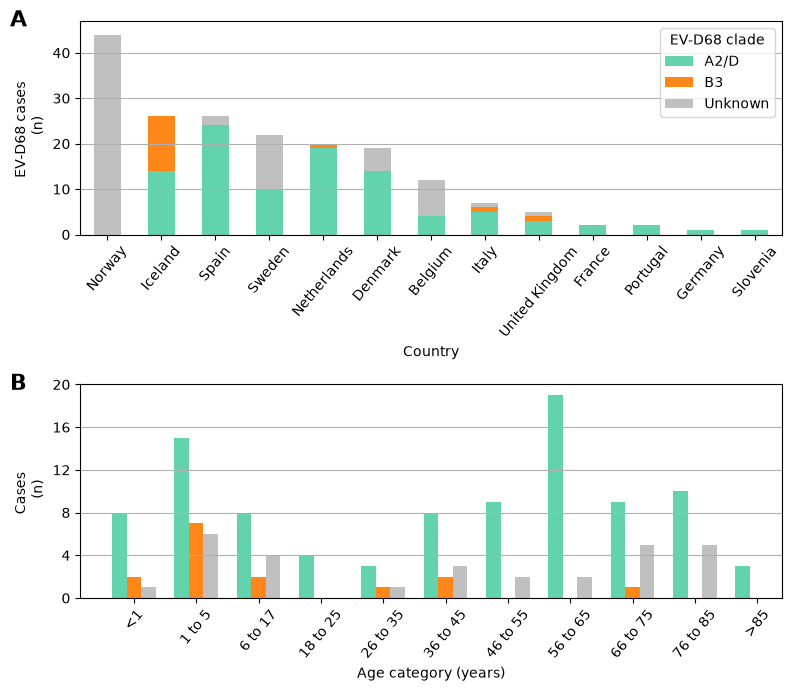

In [8]:
# === 1. Explicit order for x-axis groups ===
order_x1 = ['<1', 
          '1 to 5',
          "6 to 17",
          "18 to 25",
          "26 to 35",
          "36 to 45",
          "46 to 55",
          "56 to 65",
          "66 to 75",
          "76 to 85",
          ">85"
          #,"ND"
           ]   

# === 2. Explicit order for categories ===
order_bars = ['A2/D', 'B3', 'Unknown']

# === 3. Explicit colors for the categories ===
color_map = {
    'A2/D': '#63D3AE',
    'B3': '#FF8719',
    'Unknown': '#C0C0C0'
}

# Pivot the data so each category becomes a column
df_cases_age_nond = df_cases_age[df_cases_age['age_category'] != "ND"]
pivot_age = df_cases_age_nond.pivot(index='age_category', columns='nextclade', values='size').loc[order_x1, order_bars]

# Number of groups and categories
n_groups1 = len(order_x1)
n_cats1 = len(order_bars)
x1 = np.arange(n_groups1)  # the group positions
width1 = 0.7 / n_cats1     # bar width so all groups fit within 0.8

# Number of groups and categories
n_groups0 = len(order_x0)
n_cats0 = len(order_bars)
x0 = np.arange(n_groups0)  # the group positions
width0 = 0.7 / n_cats0     # bar width so all groups fit within 0.8

fig, ax = plt.subplots(2, figsize=(8, 7), 
                       #height_ratios=[1.5,1]
                      )
plt.rcParams['pdf.use14corefonts'] = True

# Plot each category offset horizontally
for i, cat in enumerate(order_bars):
    ax[1].bar(
        x1 + i * width1,
        pivot_age[cat],
        width1,
        label=cat,
        color=color_map[cat]
    )


# Compute total height for each category (x-axis)
totals = df_pivot_country.sum(axis=1)

# Build a DataFrame with totals + original data to allow multi-column sorting
df_tmp = df_pivot_country.copy()
df_tmp["__total__"] = totals

# Sort by:
#   1. total descending
#   2. index (category name) ascending
df_sorted_country = df_tmp.sort_values(
    by=["__total__", df_tmp.index.name],
    ascending=[False, True]
).drop(columns="__total__")

df_sorted_country.plot(
    kind="bar",
    stacked=True,
    ax=ax[0],
    color=color_map
)

ax[0].text(-0.1, .95,          # (x,y) outside top-left
        "A",
        transform=ax[0].transAxes,
        fontsize=16,
        fontweight='bold',
        va='bottom',
        ha='left'
    )

ax[1].text(-0.1, .95,          # (x,y) outside top-left
        "B",
        transform=ax[1].transAxes,
        fontsize=16,
        fontweight='bold',
        va='bottom',
        ha='left'
    )

# Formatting
ax[1].set_xticks(x1 + width1 * (n_cats1 - 1) / 2)
ax[1].set_yticks([0,4,8,12,16,20])
ax[1].set_xticklabels(order_x1, rotation =50)
ax[1].set_ylabel("Cases \n (n)")
ax[1].set_xlabel("Age category (years)")
#ax.set_title("Grouped Bar Chart (A grouped, B colored)")
ax[0].legend(title="EV-D68 clade", loc ="upper right")
ax[1].grid(visible=True, axis="y")

ax[0].set_xticklabels(df_sorted_country.index, rotation =50)
ax[0].set_xlabel("Country")
ax[0].set_ylabel("EV-D68 cases \n (n)")
ax[0].grid(visible=True, axis="y")
ax[0].set_ylim(top = totals.max()+3)

plt.tight_layout()
plt.savefig("cases_country_age.png", metadata=None, bbox_inches="tight", pad_inches=0.1)

In [9]:
## Read pivot table with fractions per clade of sewage samples
df_env = pd.read_table("wastewater.csv", sep =";")
#df_env

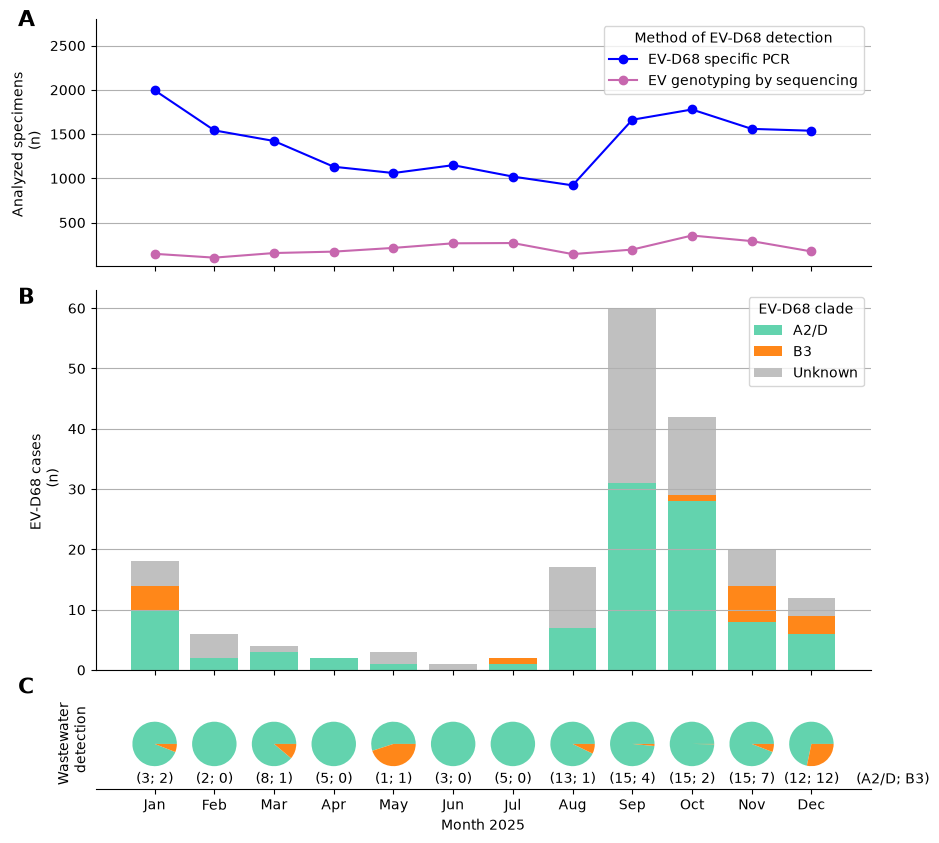

In [10]:
## CREATE FIGURE WITH SUBPLOTS
fig = plt.figure(figsize=(10, 10))
plt.rcParams['pdf.use14corefonts'] = True
gs = fig.add_gridspec(3, hspace=0.1, height_ratios=[1.3,2, .5])
axs = gs.subplots(sharex=True)          
#fig.suptitle('Sharing both axes', y=0.92)

letters = ["A", "B", "C"]

for ax, letter in zip(axs, letters):
    ax.text(
        -0.1, .95,          # (x,y) outside top-left
        letter,
        transform=ax.transAxes,
        fontsize=16,
        fontweight='bold',
        va='bottom',
        ha='left'
    )


axs[0].grid(visible=True, axis="y")
axs[1].grid(visible=True, axis="y")

## Plot specimen analysed
axs[0].plot(
    df_pcr_sum["month_num"],
    df_pcr_sum["analyzed with EV-D68 specific PCR"],
    label="EV-D68 specific PCR",
    marker="o",
    color = "blue"
)
axs[0].plot(
    df_npevseq_sum["month_num"],
    df_npevseq_sum["NPEV seq"],
    label="EV genotyping by sequencing",
    marker="o",
    color = "#C767AE"
)

axs[0].set_ylim(ymax = 2800)

## Plot clade distribution

bottom = np.zeros(len(df_pivot))

for col in df_pivot.columns:
    axs[1].bar(
        df_pivot.index,           # actual month_num values
        df_pivot[col],
        bottom=bottom,
        width=0.8,
        label=col,
        color=color_map[col]
    )
    bottom += df_pivot[col].values
axs[1].legend(title="EV-D68 clade")

## Plot pie plots of clades in wastewater
xlim = axs[0].get_xlim()

for _, row in df_env.iterrows():
    x_norm = (row["month_num"] - xlim[0]) / (xlim[1] - xlim[0])
    ax_pie = axs[2].inset_axes([
        x_norm - 0.05,
        0.15,
        0.1,
        0.65 #0.5
    ])
    
    fractions = [row["A2/D_frac"], row["B3_frac"]]
    colors = ["#63D3AE", "#FF8719"] # ["tab:purple", "tab:green"]
    ax_pie.pie(fractions, colors=colors, radius=.9)
    ax_pie.set_aspect("equal")
    ax_pie.axis("off")
    axs[2].text(                        
        x_norm, 0.03, (row["n"]),
        ha="center", va="bottom", fontsize=10,
        transform=axs[2].transAxes
    )

axs[2].text(12.75, 0.06, "(A2/D; B3)")
fig.axes[1].set_xticks([1,2,3,4,5,6,7,8,9,10,11,12])
axs[1].set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])

axs[2].set_yticks([])

axs[0].spines["top"].set_visible(False)
axs[0].spines["right"].set_visible(False)

axs[1].spines["top"].set_visible(False)
axs[1].spines["right"].set_visible(False)

axs[2].spines["top"].set_visible(False)
axs[2].spines["right"].set_visible(False)
axs[2].spines["left"].set_visible(False)

axs[0].legend(title="Method of EV-D68 detection", loc="upper right")
axs[0].set_ylabel("Analyzed specimens \n (n)")
axs[1].set_ylabel("EV-D68 cases \n (n)")
axs[2].set_ylabel("Wastewater \n detection")
axs[2].set_xlabel("Month 2025")

plt.savefig("testing_results.png", metadata=None, bbox_inches="tight", pad_inches=0.1)